# Práctica 1: riesgo de impago en préstamos

## 0. Librerías y carga de datos

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv("prestamos.csv")
print("Cargado el data frame con los siguentes datos ", df.shape)
df.head()


Cargado el data frame con los siguentes datos  (2645, 15)


,id_solicitud,fecha_solicitud,edad,ingresos_anuales,situacion_laboral,antiguedad_empleo_anios,vivienda,importe_solicitado,plazo_meses,finalidad,creditos_previos,impagos_previos,canal,gestion_recobro,impago
0,S-01477,2025-10-13,40.0,7474.0,Desempleado,0.0,Alquiler,13900.0,24,Consumo,2,1,Oficina,Sí,1
1,S-01166,2023-06-29,28.0,24852.0,Empleado,4.4,Con familia,9100.0,84,Coche,2,0,Oficina,No,0
2,S-01701,2023-06-15,55.0,NaN,Empleado,2.9,Alquiler,9850.0,84,Reforma,0,0,Oficina,No,0
3,S-01699,2023-12-22,49.0,28510.0,Empleado,1.9,Alquiler,6590.0,24,Consumo,2,0,Web,No,0
4,S-01201,2025-10-01,NaN,17555.0,Jubilado,NaN,Hipoteca,4470.0,60,Consumo,3,1,Oficina,No,0


La tabla tiene 2645 solicitudes y 15 columnas, una de las 15 columnas es el objetivo, es decir, la columna ["impago"]

## 3.1 Explorar los datos

In [47]:
print("Los datos para explorar son: ")

df.info()


Los datos para explorar son: 
<class 'pandas.DataFrame'>
RangeIndex: 2645 entries, 0 to 2644
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_solicitud             2645 non-null   str    
 1   fecha_solicitud          2645 non-null   str    
 2   edad                     2550 non-null   float64
 3   ingresos_anuales         2457 non-null   float64
 4   situacion_laboral        2645 non-null   str    
 5   antiguedad_empleo_anios  2313 non-null   float64
 6   vivienda                 2645 non-null   str    
 7   importe_solicitado       2645 non-null   float64
 8   plazo_meses              2645 non-null   int64  
 9   finalidad                2645 non-null   str    
 10  creditos_previos         2645 non-null   int64  
 11  impagos_previos          2645 non-null   int64  
 12  canal                    2645 non-null   str    
 13  gestion_recobro          2645 non-null   str    
 14  impag

Edad, ingresos_anuales, antiguedad_empleo_anios   tienen datos nulos, antiguedad de empleo es el que más tiene, casi el doble que ingresos anuales hay que seguir investigando. "fecha_solicitud" está en str cuando debería estar en formato "fecha"

In [48]:
nulos = df.isna().sum()
print("Los nulos son : \n", nulos)
porcentaje_nulos = (nulos / len(df) * 100).round(2) 
print("El porcentaje de nulos es : ")
print(porcentaje_nulos)

Los nulos son : 
 id_solicitud                 0
fecha_solicitud              0
edad                        95
ingresos_anuales           188
situacion_laboral            0
antiguedad_empleo_anios    332
vivienda                     0
importe_solicitado           0
plazo_meses                  0
finalidad                    0
creditos_previos             0
impagos_previos              0
canal                        0
gestion_recobro              0
impago                       0
dtype: int64
El porcentaje de nulos es : 
id_solicitud                0.00
fecha_solicitud             0.00
edad                        3.59
ingresos_anuales            7.11
situacion_laboral           0.00
antiguedad_empleo_anios    12.55
vivienda                    0.00
importe_solicitado          0.00
plazo_meses                 0.00
finalidad                   0.00
creditos_previos            0.00
impagos_previos             0.00
canal                       0.00
gestion_recobro             0.00
impago       

 Hay 3 columnas con nulos: En edad(3.59 por ciento), en ingresos anuales(7.11 por ciento) y en antigüedad_empleo_anios (12.55 por ciento), Esos 3 campos son los que hay que pensar en qué hacer con esos nulos y si imputar valores. No debería de borrar las filas con los nulos,  Los imputaré dentro del pipeline, después de partir los datos, para que la mediana se calcule solo con el entrenamiento

In [49]:
todos_dupli = df.duplicated().sum()
print("Los duplicados son: \n", todos_dupli)

Los duplicados son: 
 45


Tenemos 45 Duplicados, necesitamos saber de qué columna son, para ver si los podemos eliminar o si es que nos dan información extra

In [50]:
duplicados = df[df.duplicated(keep=False)].sort_values("id_solicitud")
display(duplicados.head(10))
duplicados.shape

,id_solicitud,fecha_solicitud,edad,ingresos_anuales,situacion_laboral,antiguedad_empleo_anios,vivienda,importe_solicitado,plazo_meses,finalidad,creditos_previos,impagos_previos,canal,gestion_recobro,impago
1499,S-00058,2025-04-14,34.0,20656.0,Empleado,10.6,Hipoteca,2120.0,48,Consumo,0,0,Web,No,0
1412,S-00058,2025-04-14,34.0,20656.0,Empleado,10.6,Hipoteca,2120.0,48,Consumo,0,0,Web,No,0
1809,S-00060,2025-01-05,33.0,7778.0,Desempleado,0.0,Alquiler,7610.0,12,Consumo,0,0,Web,Sí,1
1550,S-00060,2025-01-05,33.0,7778.0,Desempleado,0.0,Alquiler,7610.0,12,Consumo,0,0,Web,Sí,1
99,S-00195,2024-10-29,57.0,19954.0,Empleado,11.8,Propiedad,3450.0,12,Coche,3,0,Web,No,0
2090,S-00195,2024-10-29,57.0,19954.0,Empleado,11.8,Propiedad,3450.0,12,Coche,3,0,Web,No,0
1670,S-00331,2023-04-03,35.0,10405.0,Empleado,1.4,Alquiler,6070.0,12,Consumo,1,0,Web,Sí,1
372,S-00331,2023-04-03,35.0,10405.0,Empleado,1.4,Alquiler,6070.0,12,Consumo,1,0,Web,Sí,1
1947,S-00348,2024-07-19,53.0,16710.0,Funcionario,4.5,Propiedad,9400.0,60,Reforma,2,0,Oficina,No,0
934,S-00348,2024-07-19,53.0,16710.0,Funcionario,4.5,Propiedad,9400.0,60,Reforma,2,0,Oficina,No,0


(90, 15)

Salen 90 filas, cada id dos veces, son copias exactas

In [51]:
impagados = df["impago"].value_counts()
display(impagados)

impago
0    2388
1     257
Name: count, dtype: int64

In [52]:
df["impago"].value_counts(normalize=True)

impago
0    0.902836
1    0.097164
Name: proportion, dtype: float64

Prácticamente sin hacer nada el modelo tendría un 90,3 por ciento (accuracy) hay un 9,70 por ciento de impagados. Las clases entonces están muy desbalanceadas, hay muy pocos préstamos impagados y el que hay es muy importante acertarlo pero su recall es 0 %: no detecta ningún impago. Por eso no usaré la accuracy para elegir el modelo, sino el recall y la precisión.

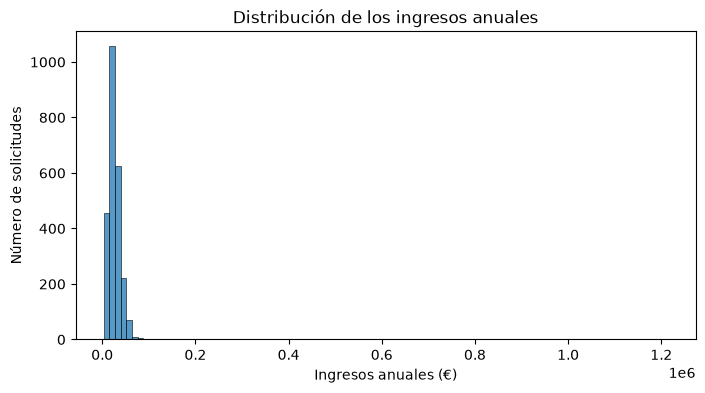

In [53]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="ingresos_anuales", ax=ax)
ax.set_title("Distribución de los ingresos anuales")
ax.set_xlabel("Ingresos anuales (€)")
ax.set_ylabel("Número de solicitudes")
plt.show()

In [54]:
display(df["ingresos_anuales"].sort_values(ascending=False).head(10))
df["ingresos_anuales"].describe().round(0)

1436    1213160.0
1926    1183800.0
35      1101920.0
1691    1021480.0
1919     381160.0
252       91341.0
311       89315.0
1150      85011.0
503       83082.0
474       79894.0
Name: ingresos_anuales, dtype: float64

count       2457.0
mean       27976.0
std        46836.0
min         3381.0
25%        17416.0
50%        24379.0
75%        32777.0
max      1213160.0
Name: ingresos_anuales, dtype: float64

In [55]:
df[df["ingresos_anuales"] > 300000]

,id_solicitud,fecha_solicitud,edad,ingresos_anuales,situacion_laboral,antiguedad_empleo_anios,vivienda,importe_solicitado,plazo_meses,finalidad,creditos_previos,impagos_previos,canal,gestion_recobro,impago
35,S-01016,2024-07-25,27.0,1101920.0,Autónomo,10.6,Propiedad,4170.0,12,Coche,0,0,Oficina,No,0
1436,S-02571,2025-07-30,63.0,1213160.0,jubilado,NaN,Alquiler,15930.0,24,Consumo,2,0,Gestor,No,0
1691,S-00070,2023-11-12,37.0,1021480.0,Empleado,2.6,Con familia,4430.0,24,Reforma,3,0,Web,No,0
1919,S-02427,2023-07-04,21.0,381160.0,Jubilado,NaN,Hipoteca,3050.0,24,Otros,3,0,Web,No,0
1926,S-02033,2023-05-07,44.0,1183800.0,Autónomo,9.2,Hipoteca,1670.0,48,Estudios,0,0,Oficina,No,0


### INTERPRETACIÓN DEL GRÁFICO 1

 La mayoría de los solicitantes gana entre 17416.0 y 32777 € al año(el 50 % central), y la mediana es 24379 €. Sin embargo, hay 4 valores por encima del millón y otro de 381160.0 €, muy separados del resto: después de ellos el siguiente valor es 91341 €. Sospecho que son erratas y no son millonarios reales porque al ver, el importe solicitado, su situación laboral y su finalidad, pues no es algo lógico para gente que gana más de 1 millón al año.
 
 Uno de ellos tiene 21 años y figura como jubilado, algo que es imposible.

Estos valores inflan la media (27976 €)  y la desviación típica (46.836€).
 
  Decidiré qué hacer con ellos en la limpieza.

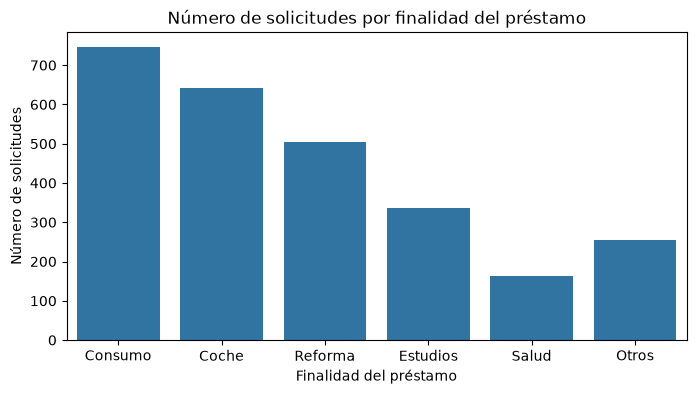

In [56]:
fig, ax = plt.subplots(figsize=(8,4))
sns.countplot(data=df, x="finalidad", ax=ax)
ax.set_title("Número de solicitudes por finalidad del préstamo")
ax.set_xlabel("Finalidad del préstamo")
ax.set_ylabel("Número de solicitudes")
plt.show()

### INTERPRETACIÓN DEL GRÁFICO 2

La mayoría de las solicitudes, son para consumo, coche, reforma o estudios, entre consumo y coche suma más de la mitad de las solicitudes, ninuna categoría es lo suficientemente pequeña como para dar problemas al modelo. No creo que aquí necesite limpieza.

In [57]:
df["finalidad"].value_counts(normalize=True).round(2)

finalidad
Consumo     0.28
Coche       0.24
Reforma     0.19
Estudios    0.13
Otros       0.10
Salud       0.06
Name: proportion, dtype: float64

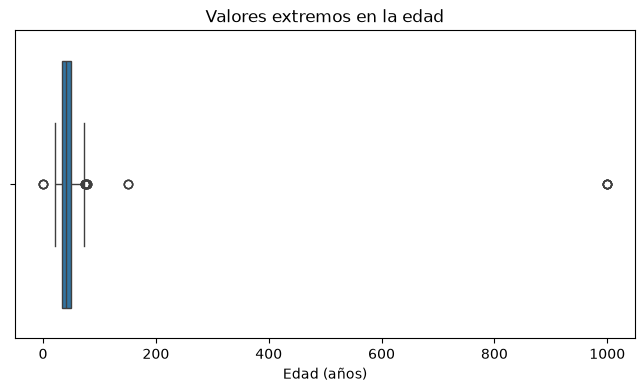

In [58]:
fig, ax = plt.subplots(figsize=(8,4))
sns.boxplot(data=df, x="edad", ax=ax)
ax.set_title("Valores extremos en la edad")
ax.set_xlabel("Edad (años)")
plt.show()

In [59]:
display(df["edad"].describe().round(1))
extremos_edad = df[(df["edad"] < 18) | (df["edad"] > 75)]
extremos_edad["edad"].value_counts().sort_index()

count    2550.0
mean       43.4
std        48.0
min         0.0
25%        33.0
50%        41.0
75%        49.0
max       999.0
Name: edad, dtype: float64

edad
0.0      4
76.0     1
78.0     4
150.0    3
999.0    6
Name: count, dtype: int64

### INTERPRETACIÓN DEL GRÁFICO 3



La mitad central de los solicitantes tiene entre 33 y 49 años y la mediana es de 41 años. Los bigotes llegan aproximadamente de los 21 a los 73 años, que son edades razonables para pedir un préstamo.

0 años (4 casos), 150 años (3) y 999 años (6): son valores imposibles. Son errores y en la limpieza los convertiré en nulos para que imputen como el resto.

76 y 78 años (5 casos) Son rarezas, pero puede ser real el valor, porque son jubilados, los mantendré 



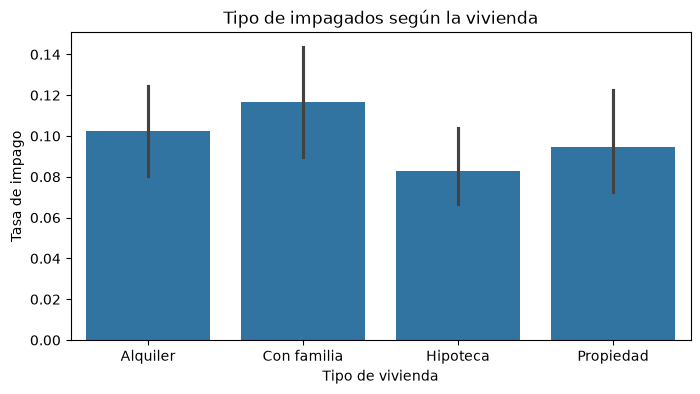

In [60]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df, x="vivienda", y="impago", ax=ax)
ax.set_title("Tipo de impagados según la vivienda")
ax.set_xlabel("Tipo de vivienda")
ax.set_ylabel("Tasa de impago")
plt.show()

In [61]:
df.groupby("vivienda")["impago"].mean().round(3)

vivienda
Alquiler       0.102
Con familia    0.117
Hipoteca       0.083
Propiedad      0.095
Name: impago, dtype: float64

### INTEPRETACIÓN 4 GRÁFICO

La tasa de impago cambia algo según el tipo de vivienda, los que vive con familia son los que más impagan, los que tienen hipoteca son los que menos impagan, aun así son diferencias muy pequeñas, la vivienda parece ser una variable poco definitiva con respecto al impago, la voy a mantener en el modelo

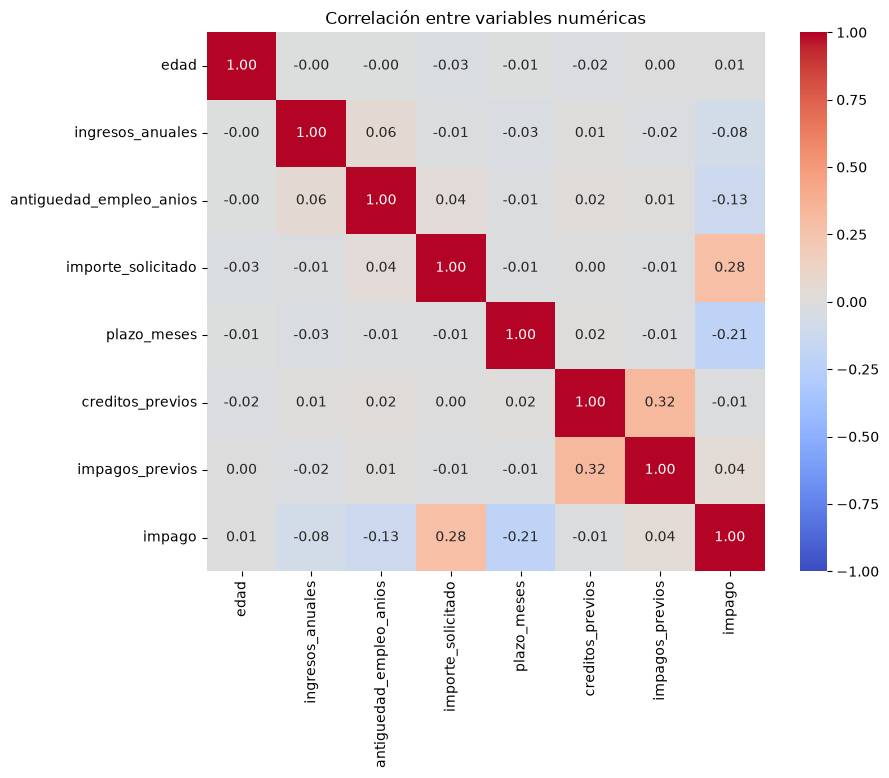

In [62]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df.select_dtypes("number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",vmin=-1, vmax=1, ax=ax) 
ax.set_title("Correlación entre variables numéricas")
plt.show()


### INTERPRETACIÓN GRÁFICO 5

Impago tiene una correlación media con importe solicitado (0,28) cosa que tiene sentido, ya que al pedir más importe es más difícil devolverlo, con plazo meses tiene un -0,21, también tiene sentido, ya que al tener más meses, la cuota mensual es más baja, lo que me sorprende mucho es la baja correlación con impagos_previos(0,04), ya que uno espera que quien ya impagó vuelva a hacerlo

Ninguna correlación con impago es fuerte (todas con menos de 0,3), eso quiere decir que ninguna variable predice bien el impago, el modelo tendrá que combinarlas, además la correlación solo mide relaciones lineales y solo entre variables numéricas.

In [63]:
situacion = df["situacion_laboral"].str.strip().str.capitalize()
nulo_antig = df["antiguedad_empleo_anios"].isna()
nulo_antig.groupby(situacion).mean().round(3)

situacion_laboral
Autónomo       0.037
Desempleado    0.033
Empleado       0.044
Funcionario    0.050
Jubilado       1.000
Name: antiguedad_empleo_anios, dtype: float64

In [64]:
nulo_antig.groupby(df["impago"]).mean().round(3)



impago
0    0.126
1    0.117
Name: antiguedad_empleo_anios, dtype: float64

## 3.2 limpiar los datos 

In [65]:
df = df.drop_duplicates()
print("Filas después de quitar duplicados: ", df.shape)

Filas después de quitar duplicados:  (2600, 15)


 Elimino los 45 duplicados porque son copias exactas (mismo id y mismos datos) no aportan información y harían que el modelo diera más peso a esas solicitudes.

In [66]:
print("Antes: ", df["situacion_laboral"].nunique(), "categorias")

df["situacion_laboral"] = df["situacion_laboral"].str.strip().str.capitalize()

print("Después: ", df["situacion_laboral"].nunique(),"categorias")
df["situacion_laboral"].value_counts()

Antes:  25 categorias
Después:  5 categorias


situacion_laboral
Empleado       1448
Autónomo        394
Funcionario     295
Desempleado     237
Jubilado        226
Name: count, dtype: int64

La columna tenía 25 formas distintas de escribir solo 5 situaciones ("EMPLEADO", " Empleado", "empleado "...). Para el modelo serían categorías diferentes, así que quito los espacios y dejo solo la primera letra en mayúscula.

In [67]:
imposibles = (df["edad"] < 18) | (df["edad"] > 100)
print("Edades imposibles: ", imposibles.sum())

df.loc[imposibles, "edad"] = np.nan
print("Nulos en edad ahora: ", df["edad"].isna().sum())

Edades imposibles:  13
Nulos en edad ahora:  103


Las edades de 0, 150 y 999 son errores. No borramos las filas, porque el resto de sus datos sirve. Solo vaciamos la edad (la ponemos como nulo) y el pipeline la rellenará después con la mediana, igual que los demás nulos.

In [68]:
ingresos_raros = (df["ingresos_anuales"] > 300000)
display(ingresos_raros.sum())
df.loc[ingresos_raros, "ingresos_anuales"] = np.nan
print("nulos en ingresos ahora: ", df["ingresos_anuales"].isna().sum())

np.int64(5)

nulos en ingresos ahora:  190


Los 5 ingresos de más de 300 000 € son casi seguro errores: piden préstamos pequeños y uno es un jubilado de 21 años. No borro las filas, convierto esos ingresos en nulos y el pipeline los rellenará con la mediana

In [69]:
df["fecha_solicitud"] = pd.to_datetime(df["fecha_solicitud"], errors="coerce")
print(df["fecha_solicitud"].dtypes)
print("Fechas no válidas: ", df["fecha_solicitud"].isna().sum())

datetime64[us]
Fechas no válidas:  0


La fecha venía como texto, así que la paso a formato fecha con pd.to_datetime. Con errors="coerce", si alguna no se pudiera leer quedaría como nulo en vez de romper el código, pero salen 0 fechas no válidas: todas estaban bien escritas. Ahora podré sacar de ella el año o el mes como variables nuevas en el apartado 3.3.


In [70]:
df = df.drop(columns="id_solicitud")
print("Forma después de quitar el id: ", df.shape)

Forma después de quitar el id:  (2600, 14)


Quito id_solicitud porque es solo un identificador: cada solicitud tiene uno distinto y no dice nada del cliente. Si lo dejara, el modelo podría memorizar filas concretas en vez de aprender patrones que sirvan para solicitudes nuevas. Quedan 2600 filas y 14 columnas.


In [71]:
print((df["importe_solicitado"] == 60000).sum())
display(df["importe_solicitado"].sort_values(ascending=False).head(15))
df.loc[df["importe_solicitado"] == 60000, "impago"].mean()

10


604     60000.0
2569    60000.0
2502    60000.0
424     60000.0
716     60000.0
1434    60000.0
527     60000.0
207     60000.0
234     60000.0
1393    60000.0
1553    58390.0
638     57700.0
22      53200.0
1498    52170.0
791     51420.0
Name: importe_solicitado, dtype: float64

np.float64(0.8)

Hay 10 préstamos de exactamente 60 000 €, el importe más alto. A diferencia de los ingresos, aquí no hay un salto raro: el siguiente valor es 58 390 €, así que parece el tope máximo que da el banco y no un error. Además, el 80 % de estos préstamos acabó en impago, frente al 9,7 % general, lo que encaja con que el importe sea la variable más relacionada con el impago (0,28). Los dejo tal cual: si los convirtiera en nulos, el pipeline los rellenaría con la mediana, parecerían préstamos normales y el modelo perdería justo la información que más le sirve.


In [72]:
jubilado_sin_antig = (df["situacion_laboral"] == "Jubilado") & (df["antiguedad_empleo_anios"].isna())
print("Jubilados sin antigüedad: ", jubilado_sin_antig.sum())
df.loc[jubilado_sin_antig, "antiguedad_empleo_anios"] = 0
print("Nulos que quedan en antigüedad: ", df["antiguedad_empleo_anios"].isna().sum())



Jubilados sin antigüedad:  226
Nulos que quedan en antigüedad:  98


### 3.3 Crear Variables nuevas

In [73]:
df["cuota_mensual"] = df["importe_solicitado"] / df["plazo_meses"]
display(df[["importe_solicitado", "plazo_meses", "cuota_mensual"]].head(5))
df["cuota_mensual"].describe().round(0)

,importe_solicitado,plazo_meses,cuota_mensual
0,13900.0,24,579.166667
1,9100.0,84,108.333333
2,9850.0,84,117.261905
3,6590.0,24,274.583333
4,4470.0,60,74.500000


count    2600.0
mean      338.0
std       377.0
min        14.0
25%       124.0
50%       222.0
75%       414.0
max      5000.0
Name: cuota_mensual, dtype: float64

Creo la cuota mensual (importe / plazo) porque lo que aprieta al cliente no es solo cuánto pide, sino cuánto tiene que pagar cada mes. Es una cuota aproximada, sin intereses. La mitad de los clientes paga menos de 222 € al mes y el 75 % menos de 414 €. El máximo, 5 000 €, no es un error: sale de un préstamo de 60 000 € a 12 meses. Esta variable se calcula con la propia fila, así que puedo crearla antes del split sin fuga.


In [74]:
df["esfuerzo"] = (df["cuota_mensual"] * 12) / df["ingresos_anuales"]
display(df[["cuota_mensual", "ingresos_anuales", "esfuerzo"]].head())
df["esfuerzo"].describe().round(2)

,cuota_mensual,ingresos_anuales,esfuerzo
0,579.166667,7474.0,0.929890
1,108.333333,24852.0,0.052310
2,117.261905,NaN,NaN
3,274.583333,28510.0,0.115573
4,74.500000,17555.0,0.050926


count    2410.00
mean        0.20
std         0.28
min         0.00
25%         0.06
50%         0.11
75%         0.23
max         4.03
Name: esfuerzo, dtype: float64

Creo el esfuerzo: la parte de los ingresos anuales que se va en pagar el préstamo (cuota mensual × 12 / ingresos anuales). Pedir 500 € al mes no pesa igual para todos, esta variable lo pone en relación con lo que gana cada uno. La mitad de los clientes dedica menos del 11 % de sus ingresos y el 75 % menos del 23 %, pero hay casos extremos de hasta 4,03 (pagaría cuatro veces lo que gana en un año). Hay 2410 valores porque faltan 190 ingresos, esos nulos los rellenará el pipeline.


In [75]:
df["anio_solicitud"] = df["fecha_solicitud"].dt.year
df["mes_solicitud"] = df["fecha_solicitud"].dt.month
display(df[["fecha_solicitud", "anio_solicitud", "mes_solicitud"]].head())

df.groupby("anio_solicitud")["impago"].mean().round(3)


,fecha_solicitud,anio_solicitud,mes_solicitud
0,2025-10-13,2025,10
1,2023-06-29,2023,6
2,2023-06-15,2023,6
3,2023-12-22,2023,12
4,2025-10-01,2025,10


anio_solicitud
2023    0.087
2024    0.088
2025    0.117
Name: impago, dtype: float64

Saco el año y el mes de la fecha de solicitud, porque el modelo no sabe trabajar con fechas directamente pero sí con números. La tasa de impago es parecida en 2023 y 2024 (0,087 y 0,088) y sube algo en 2025 (0,117). La diferencia es pequeña, pero puede reflejar un cambio en el tipo de clientes o en la situación económica, así que mantengo estas variables para que el modelo decida si le sirven.


In [76]:
df = df.drop(columns=["fecha_solicitud"])
print("Forma después de quitar la fecha: ", df.shape)

Forma después de quitar la fecha:  (2600, 17)


Quito fecha_solicitud porque ya he sacado de ella el año y el mes, y el modelo no puede trabajar con fechas directamente. Quedan 2600 filas y 17 columnas.


In [77]:
from sklearn.model_selection import train_test_split

y = df["impago"]
X = df.drop(columns=["impago", "gestion_recobro"])

X_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print("Train: ", X_train.shape, " Test:", x_test.shape)
print("% impago train: ", y_train.mean().round(3), " test", y_test.mean().round(3))

Train:  (2080, 15)  Test: (520, 15)
% impago train:  0.097  test 0.098


Separo la variable a predecir (impago) del resto. Dejo fuera gestion_recobro porque el banco solo la conoce después de que el cliente deje de pagar: es fuga de información. Parto los datos 80/20 con stratify=y para que los dos grupos tengan la misma proporción de impagos (9,7 % en train y 9,8 % en test) y con random_state=42 para que el reparto sea siempre el mismo. Train queda con 2080 filas y test con 520.


In [78]:
num_cols = X_train.select_dtypes("number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numéricas: ", len(num_cols), num_cols)
print("Categóricas: ", len(cat_cols), cat_cols)

Numéricas:  11 ['edad', 'ingresos_anuales', 'antiguedad_empleo_anios', 'importe_solicitado', 'plazo_meses', 'creditos_previos', 'impagos_previos', 'cuota_mensual', 'esfuerzo', 'anio_solicitud', 'mes_solicitud']
Categóricas:  4 ['situacion_laboral', 'vivienda', 'finalidad', 'canal']


Separo las columnas por tipo porque el pipeline las trata distinto: a las 11 numéricas les relleno nulos y las escalo; a las 4 categóricas les relleno nulos y las convierto en columnas de 0 y 1.


In [79]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

num_pipe = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])

cat_pipe = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocesado = ColumnTransformer([
    ("num", num_pipe,num_cols),
    ("cat", cat_pipe, cat_cols),
])

modelo = Pipeline([
    ("prep", preprocesado),
    ("modelo", LogisticRegression(max_iter=1000))
])

modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output

Monto todo el preprocesado dentro de un pipeline. A las columnas numéricas les relleno los nulos con la mediana y las escalo; a las categóricas les relleno los nulos con la categoría más frecuente y las paso a columnas de 0 y 1. El modelo regresión logística va como último paso. Así, la mediana, la escala y las categorías se aprenden solo con los datos de entrenamiento cuando haga .fit, y el test no influye en nada.


In [80]:
modelo.fit(X_train, y_train)
y_pred= modelo.predict(x_test)

print("Predicciones:", len(y_pred))
print("¿Cuántos impagos predice?:", y_pred.sum())
print("¿Cuántos impagos hay de verdad en test?:", y_test.sum())

Predicciones: 520
¿Cuántos impagos predice?: 26
¿Cuántos impagos hay de verdad en test?: 51


In [81]:
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score
from sklearn.dummy import DummyClassifier

trivial = DummyClassifier(strategy="most_frequent")
trivial.fit(X_train, y_train)
y_trivial = trivial.predict(x_test)

for nombre, pred in [["Trivial", y_trivial], ("Logística", y_pred)]:
    print(nombre)
    print("  Accuracy :", round(accuracy_score(y_test, pred), 3))
    print("  Recall   :", round(recall_score(y_test, pred), 3))
    print("  Precisión:", round(precision_score(y_test, pred, zero_division=0), 3))

print(confusion_matrix(y_test, y_pred))

Trivial
  Accuracy : 0.902
  Recall   : 0.0
  Precisión: 0.0
Logística
  Accuracy : 0.925
  Recall   : 0.373
  Precisión: 0.731
[[462   7]
 [ 32  19]]


In [82]:
# Mismo preprocesado, pero el modelo da más peso a los impagos
modelo_bal = Pipeline([
    ("prep", preprocesado),
    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

modelo_bal.fit(X_train, y_train)
y_pred_bal = modelo_bal.predict(x_test)

# Comparo los tres
for nombre, pred in [("Trivial", y_trivial), ("Logística", y_pred), ("Logística balanceada", y_pred_bal)]:
    print(nombre)
    print("  Accuracy :", round(accuracy_score(y_test, pred), 3))
    print("  Recall   :", round(recall_score(y_test, pred), 3))
    print("  Precisión:", round(precision_score(y_test, pred, zero_division=0), 3))

print(confusion_matrix(y_test, y_pred_bal))


Trivial
  Accuracy : 0.902
  Recall   : 0.0
  Precisión: 0.0
Logística
  Accuracy : 0.925
  Recall   : 0.373
  Precisión: 0.731
Logística balanceada
  Accuracy : 0.856
  Recall   : 0.647
  Precisión: 0.367
[[412  57]
 [ 18  33]]


Para tratar el desbalanceo uso class_weight="balanced", que hace que equivocarse con un impago cuente más que equivocarse con un cliente que paga. El recall sube de 0,373 a 0,647: ahora detecta 33 de los 51 impagos y solo se le escapan 18 (antes, 32). A cambio, la precisión baja de 0,731 a 0,367 y hay 57 falsas alarmas (antes, 7). La accuracy también baja (0,856), pero eso no me preocupa porque ya vimos que engaña.

Me quedo con el modelo balanceado. Para el banco, un préstamo que no se devuelve cuesta miles de euros, mientras que una falsa alarma solo significa revisar con más cuidado una solicitud que al final era buena. Prefiero revisar de más que dejar escapar impagos.


### 3.6 Fuga

In [83]:
pd.crosstab(df["gestion_recobro"], df["impago"])


X_fuga = df.drop(columns=["impago"])

# Mismo reparto (mismo random_state y stratify → mismas filas que antes)
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_fuga, y, test_size=0.20, stratify=y, random_state=42)

# gestion_recobro es texto, añado a las categoricas
prep_fuga = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols + ["gestion_recobro"
    ""]),
])

modelo_fuga = Pipeline([
    ("prep", prep_fuga),
    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

modelo_fuga.fit(Xf_train, yf_train)
y_pred_fuga = modelo_fuga.predict(Xf_test)

print("Recall   :", round(recall_score(yf_test, y_pred_fuga), 3))
print("Precisión:", round(precision_score(yf_test, y_pred_fuga), 3))
print(confusion_matrix(yf_test, y_pred_fuga))



Recall   : 0.843
Precisión: 0.811
[[459  10]
 [  8  43]]


Con cada columna me he hecho la misma pregunta: ¿tendría el banco este dato en el momento de aprobar o rechazar el préstamo? Todas pasan el filtro menos una, gestion_recobro. Una gestión de recobro solo se abre cuando el cliente ya ha dejado de pagar. No avisa del impago, viene después. La tabla cruzada lo deja claro: de los [ ] impagos, [ ] tienen gestión de recobro.

Si la meto en el modelo, las métricas se disparan. El recall pasa de 0,647 a 0,843, la precisión de 0,367 a 0,811 y solo se escapan 8 impagos. Pero hay truco. Cuando llega una solicitud nueva, ese campo todavía no existe, así que en la vida real el modelo fallaría bastante más de lo que dicen esos números. Por eso la he dejado fuera del modelo final.